**Vision-Based Gaze Estimation | Presented by: Reza Saadatyar (2026)**

**02 | Eye Images, Geometry and Data Quality**

![MPIIGaze image preparation, recorded sample quality and participant-disjoint folds](../../images/02_eye_images_geometry_and_quality.svg)

**Objective:** Prepare normalised left-eye images and their associated gaze labels for unseen-person gaze estimation.

**Data:** The executed decoder processed 213,658 left-eye rows from 521 normalised MAT containers and retained 7,500 images (500 per participant, 15 participants). Each image is 36 × 60 pixels; its target is represented by a 3D unit vector.

**Evaluation:** Fifteen outer leave-one-person-out (LOPO) folds use 12 Training, two inner Validation and one Test participant per fold. The selected cohort is a study-defined subset, not the publisher's official Evaluation Subset.

**00. Colab Repository Setup**


In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess
repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/",1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git","clone","-q",repo_url,str(repo_path)],check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}

/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**


In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("vision_based_gaze_estimation")

# ---------------------------- 2. Standard Library ----------------------------
import sys

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

# ----------------- 5. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab
from mpiigaze_data import build_eye_sample_cache
from mpiigaze_io import (ensure_mpiigaze_source, normalised_mat_files,
                         is_normalised_mat_path)
from gaze_evaluation import participant_fold_table
from gaze_geometry import angular_error_degrees

# ------------------- 6. Output Directory and Setup Summary -------------------
out_dir = root / "vision_based_gaze_estimation" / "output"
out_dir.mkdir(parents=True, exist_ok=True)
raw_dir = root / "data" / "raw" / "mpiigaze"
processed_dir = root / "data" / "processed" / "mpiigaze"
processed_dir.mkdir(parents=True, exist_ok=True)
cache_path = processed_dir / "02_normalised_eye_cache.npz"
plot_style(font_family="DejaVu Sans", title_size=12.5,
           title_weight="normal", label_size=11.5,
           label_weight="normal", tick_size=11, legend_size=10,
           figure_dpi=100, figure_size=(9,4))
print("Study outputs:",out_dir)
print("Git-ignored image cache:",cache_path)
print("Python:",sys.version.split()[0])

Repository up to date.
Study outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/vision_based_gaze_estimation/output
Git-ignored image cache: /content/Eye-Tracking-Neurocognitive-Intelligence/data/processed/mpiigaze/02_normalised_eye_cache.npz
Python: 3.13.16


**02. Validate Notebook-01 Source Inputs**

Reconcile relative paths and byte sizes of the normalised MAT containers with the Notebook 01 inventory. The recorded run matched all 521 participant/day paths before decoding.

In [3]:
# ================== 02. Verify Source and Dataset Contract ===================


inventory_path = out_dir / "01_file_inventory.csv"
if not inventory_path.is_file():
    raise FileNotFoundError(f"Run Notebook 01 to create {inventory_path}")
inventory = pd.read_csv(inventory_path)
if inventory.empty or inventory.relative_path.duplicated().any():
    raise ValueError("Source inventory is empty or contains duplicate paths")
# -------------------- 2. Reuse or Recover Runtime Source ---------------------
raw_dir = ensure_mpiigaze_source(raw_dir)
expected = inventory.loc[
    inventory.relative_path.map(is_normalised_mat_path),
    ["relative_path", "size_bytes"]]
expected = {
    row.relative_path: int(row.size_bytes)
    for row in expected.itertuples(index=False)
}
observed = {
    path.relative_to(raw_dir).as_posix(): path.stat().st_size
    for path in normalised_mat_files(raw_dir)
}
if not expected or expected != observed:
    raise ValueError(
        "The current normalised source differs from the Notebook-01 "
        "inventory. Rerun Notebook 01 against this release before continuing.")
print("Observed original source files:",len(inventory))
print("Participant/day MAT paths:", len(observed))

Reusing MPIIGaze runtime cache: /content/Eye-Tracking-Neurocognitive-Intelligence/data/raw/mpiigaze
Normalised MAT containers: 521
Observed original source files: 430180
Participant/day MAT paths: 521


**03. Decode a Source-Matched Image Sample**

Read the left-eye image and gaze fields from each normalised MAT file, preserving participant, file, eye and row identity. The decoder accepts supported angle or vector representations, converts them to 3D unit directions and checks image/target row counts.

Deterministic reservoir sampling (seed 17) retains 500 rows independently per participant without selecting on gaze values. The source yielded 213,658 rows, one fewer than the published image count of 213,659; the reason is unresolved and the counts describe different reporting scopes. The retained 7,500 images have shape (7,500, 36, 60). All saved sample IDs are unique and all saved target norms agree with unity within numerical tolerance. Row-count alignment and norm checks do not independently establish the physical gaze-axis convention.

In [4]:
# ================== 03. Extract Matched Gaze and Eye Images ==================

# ------------------------ 1. Define the Source Subset ------------------------
SOURCE_EYE = "left"
MAX_IMAGES_PER_PERSON = 500
SEED = 17

# ----------------------- 2. Read Original MATLAB Rows ------------------------
records,images,gaze,source_counts = build_eye_sample_cache(
    raw_dir,eye=SOURCE_EYE,per_person=MAX_IMAGES_PER_PERSON,seed=SEED)
samples = pd.DataFrame(records)
if samples.sample_id.duplicated().any() or samples.empty:
    raise ValueError("Image sample identities are missing or duplicated")
if not np.allclose(np.linalg.norm(gaze,axis=1),1.,atol=1e-5):
    raise ValueError("The original 3D gaze vectors are not unit length")
print("Source image rows inspected:",sum(source_counts.values()))
print("Selected source-matched samples:",len(samples))
print("Image dimensions:",images.shape)
display(samples.groupby("participant_id").size().rename("images"))

Source image rows inspected: 213658
Selected source-matched samples: 7500
Image dimensions: (7500, 36, 60)


,images
participant_id,
p00,500
p01,500
p02,500
p03,500
p04,500
p05,500
p06,500
p07,500
p08,500


**04. Define Nested Participant-Disjoint Folds**

Each of the 15 outer folds assigns all images of a participant to one role: 12 Training people (6,000 images), two inner Validation people (1,000 images) and one Test person (500 images). Every participant is held out exactly once. Ridge tuning and neural checkpoint selection use inner Validation only; outer Test is reserved for final evaluation.

In [5]:
# ================= 04. Define Independent-Person Evaluation ==================

folds = participant_fold_table(
    samples.participant_id.unique(),seed=SEED,inner_people=2)
outer = folds.loc[folds.role.eq("test")]
if outer.participant_id.duplicated().any() or set(outer.participant_id)!=set(samples.participant_id):
    raise ValueError("Outer fold assignments are not participant-disjoint")
print("Outer LOPO folds:",folds.fold_id.nunique())
display(folds.groupby(["fold_id","role"]).size().unstack(fill_value=0))

Outer LOPO folds: 15


role,test,train,validation
fold_id,,,
outer_01,1,12,2
outer_02,1,12,2
outer_03,1,12,2
outer_04,1,12,2
outer_05,1,12,2
outer_06,1,12,2
outer_07,1,12,2
outer_08,1,12,2
outer_09,1,12,2


**05. Inspect Pixel Quality and Geometry**

For each grayscale image, calculate the mean intensity and pixel standard deviation. The latter is a descriptive contrast measure, not a clinical or annotation-quality score. Across the saved 7,500 rows, mean intensities range from 83.87 to 216.38 and pixel SD from 66.67 to 86.94. All are finite. Mean contrast by participant ranges from 73.01 to 75.27.

Local eye-crop inspection illustrates the image format. The angular-error identity check evaluates a direction against itself (approximately 0°); it does not independently validate the source coordinate convention.

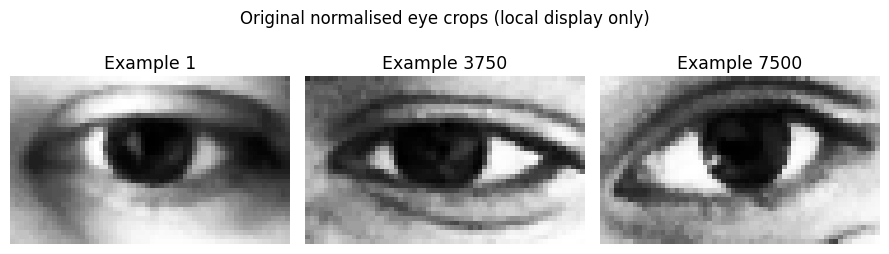

In [6]:
# ==================== 05. Inspect Original Image Quality =====================

flat = images.reshape(len(images),-1).astype(np.float32)
samples["mean_pixel_intensity"] = flat.mean(axis=1)
samples["pixel_std"] = flat.std(axis=1)
if not np.isfinite(samples[["mean_pixel_intensity","pixel_std"]]).all().all():
    raise ValueError("Non-finite image statistics")
fig,axes=plt.subplots(1,3,figsize=(9,2.8))
for ax,idx in zip(axes,np.linspace(0,len(images)-1,3,dtype=int)):
    ax.imshow(images[idx],cmap="gray",vmin=0,vmax=255)
    ax.set(title=f"Example {idx+1}")
    ax.axis("off")
fig.suptitle("Original normalised eye crops (local display only)")
fig.tight_layout()
plt.show()
if not np.allclose(angular_error_degrees(gaze[:1],gaze[:1]),[0.],atol=.05):
    raise ValueError("Angular-error identity check failed")

**06. Save Canonical Stage-02 Outputs**

Store the sample index, participant fold assignments, source/selected counts and sampling settings as CSV. The quality plot summarises balanced participant counts and observed contrast. The local NPZ contains images, gaze vectors and ordered sample IDs; subsequent modelling checks its correspondence with the saved index. Raw image arrays remain outside Git.

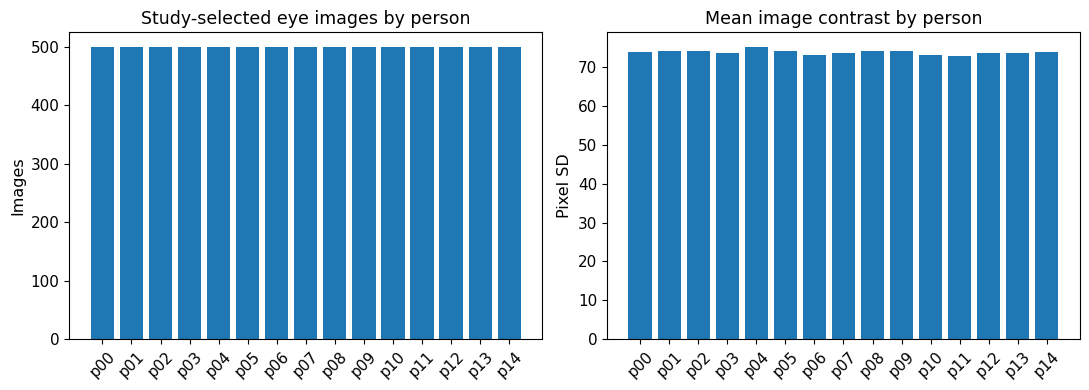

In [7]:
# ================= 06. Save Image and Participant Contracts ==================

# ----------------------- 1. Save Sample and Fold Data ------------------------
samples.to_csv(out_dir / "02_sample_index.csv", index=False)
folds.to_csv(out_dir / "02_fold_assignments.csv", index=False)
pd.DataFrame([
    {
        "participant_id": person,
        "source_image_samples": count,
        "selected_image_samples": int(samples.participant_id.eq(person).sum()),
    }
    for person, count in sorted(source_counts.items())
]).to_csv(out_dir / "02_source_sample_counts.csv", index=False)
np.savez_compressed(
    cache_path, images=images, gaze=gaze,
    sample_id=samples.sample_id.to_numpy(dtype=str),
)

# -------------------------- 2. Save Cache Settings ---------------------------
settings = {
    "local_cache": cache_path.relative_to(root).as_posix(),
    "eye": SOURCE_EYE, "max_per_person": MAX_IMAGES_PER_PERSON,
    "seed": SEED, "selected_samples": len(samples),
    "official_evaluation_subset": False,
}
pd.DataFrame(settings.items(), columns=["setting", "value"]).to_csv(
    out_dir / "02_cache_location.csv", index=False)

# --------------------------- 3. Plot Image Quality ---------------------------
quality=samples.groupby("participant_id").agg(n=("sample_id","size"),
 mean_contrast=("pixel_std","mean")).reset_index()
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].bar(quality.participant_id,quality.n)
axes[0].set(title="Study-selected eye images by person",ylabel="Images")
axes[1].bar(quality.participant_id,quality.mean_contrast)
axes[1].set(title="Mean image contrast by person",ylabel="Pixel SD")
for ax in axes: ax.tick_params(axis="x",rotation=45)
fig.tight_layout()
save_figure(fig,out_dir/"02_image_quality.png")
plt.show()

**07. Interpretation and Output Download**

The recorded data-preparation stage produces 7,500 unique left-eye samples from all 15 participants and 15 participant-disjoint outer folds. The five exported files describe the study cohort, fold roles and pixel quality; the image cache remains local. The one-row source-count difference and independent confirmation of the gaze coordinate convention remain interpretation limits.

Notebook 03 compares a training-derived mean gaze direction with HOG + Ridge using these exact sample identities and fold roles. No model has been fitted in Notebook 02.

In [8]:
# ==================== 07. Interpret Study Data and Export ====================

expected=["02_sample_index.csv","02_fold_assignments.csv",
"02_source_sample_counts.csv","02_cache_location.csv","02_image_quality.png"]
missing=[p for p in expected if not (out_dir/p).is_file()]
if missing or not cache_path.is_file():
    raise FileNotFoundError(f"Stage-02 outputs/cache missing: {missing}")
print("Selected people:",samples.participant_id.nunique())
print("Source-linked images:",len(samples))
print("Next: 03_classical_gaze_estimation_baselines.ipynb")
(out_dir / "02_cache_location.json").unlink(missing_ok=True)
download_outputs_from_colab("vision_based_gaze_estimation/output","02")

Selected people: 15
Source-linked images: 7500
Next: 03_classical_gaze_estimation_baselines.ipynb
------------------------------------------------------------------------
Notebook 02
Files packaged: 5
  + 02_cache_location.csv
  + 02_fold_assignments.csv
  + 02_image_quality.png
  + 02_sample_index.csv
  + 02_source_sample_counts.csv
Download ZIP from Colab Contents: /content/vision_based_gaze_estimation_Notebook_02_Outputs.zip
